# Hypothesis Testing — Demo

**Course:** Machine Learning Foundation  
**Topic:** Hipotesis nol, hipotesis alternatif, p-value, cutoff, serta Type I dan Type II error.

Contoh mengikuti skenario pembelajaran: seseorang mengklaim mampu menebak hasil lemparan koin lebih baik daripada peluang acak.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

## 1. Merumuskan hipotesis

- **Hipotesis nol (H₀):** peluang tebakan benar adalah 0,5, sama seperti tebakan acak.
- **Hipotesis alternatif (H₁):** peluang tebakan benar lebih besar dari 0,5.

Misalkan dilakukan 100 tebakan dan 57 di antaranya benar. Kita hitung peluang mendapatkan setidaknya 57 jawaban benar jika H₀ benar.

In [2]:
n = 100
p_null = 0.5
observed_correct = 57
alpha = 0.05

# P(X >= 57) = 1 - P(X <= 56)
p_value = binom.sf(observed_correct - 1, n, p_null)
print(f"P-value: {p_value:.4f} ({p_value:.2%})")
if p_value < alpha:
    print("Tolak H0 pada taraf signifikansi 5%.")
else:
    print("Belum cukup bukti untuk menolak H0 pada taraf signifikansi 5%.")

P-value: 0.0967 (9.67%)
Belum cukup bukti untuk menolak H0 pada taraf signifikansi 5%.


## 2. Menentukan cutoff untuk taraf signifikansi 5%

Cari jumlah tebakan benar minimum yang membuat peluang hasil setidaknya sebesar itu di bawah H₀ tidak melebihi 5%.

In [3]:
possible_counts = np.arange(n + 1)
tail_probs = binom.sf(possible_counts - 1, n, p_null)
valid_cutoffs = possible_counts[tail_probs <= alpha]
cutoff = int(valid_cutoffs[0]) if len(valid_cutoffs) else None
print("Cutoff minimum:", cutoff)
print("Peluang ekor pada cutoff:", f"{binom.sf(cutoff - 1, n, p_null):.2%}" if cutoff is not None else "Tidak ada")

Cutoff minimum: 59
Peluang ekor pada cutoff: 4.43%


## 3. Membandingkan hipotesis peluang 50% dan 60%

Kita bandingkan peluang mendapatkan 57 atau lebih jawaban benar bila peluang benar sebenarnya 50%, dengan peluang memperoleh 57 atau kurang bila peluang sebenarnya 60%. Kedua nilai ini membantu memahami bahwa keputusan statistik juga dipengaruhi jumlah sampel dan cutoff.

In [4]:
p_false_positive_at_57 = binom.sf(56, 100, 0.5)
p_false_negative_at_57 = binom.cdf(57, 100, 0.6)
print(f"P(X >= 57 | p=0.5): {p_false_positive_at_57:.2%}")
print(f"P(X <= 57 | p=0.6): {p_false_negative_at_57:.2%}")

P(X >= 57 | p=0.5): 9.67%
P(X <= 57 | p=0.6): 30.33%


## 4. Menggambarkan distribusi pendekatan normal

Grafik ini mengilustrasikan dua klaim yang berbeda. Ini merupakan ilustrasi konseptual dengan simpangan baku yang ditetapkan untuk visualisasi, bukan perhitungan parameter binomial yang presisi.

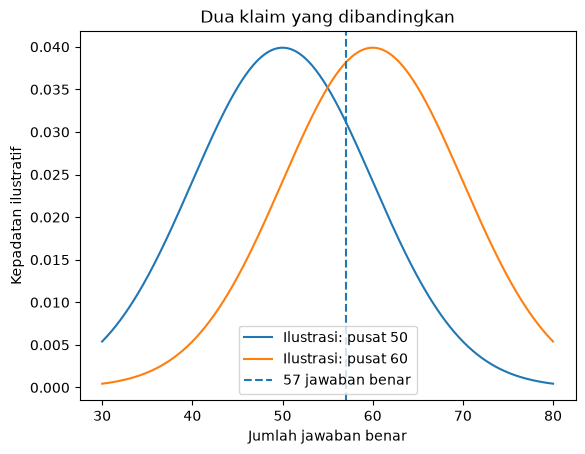

In [5]:
x = np.linspace(30, 80, 500)
plt.plot(x, norm.pdf(x, loc=50, scale=10), label="Ilustrasi: pusat 50")
plt.plot(x, norm.pdf(x, loc=60, scale=10), label="Ilustrasi: pusat 60")
plt.axvline(57, linestyle="--", label="57 jawaban benar")
plt.xlabel("Jumlah jawaban benar")
plt.ylabel("Kepadatan ilustratif")
plt.title("Dua klaim yang dibandingkan")
plt.legend()
plt.show()

## 5. Dampak ukuran sampel

Dengan sampel yang lebih besar, perbedaan antara peluang 0,5 dan 0,6 cenderung lebih mudah dideteksi. Untuk 1.000 percobaan, kita dapat menghitung peluang kesalahan pada cutoff tertentu.

In [6]:
n_large = 1000
cutoff_large = 550
type_i = binom.sf(cutoff_large - 1, n_large, 0.5)
type_ii = binom.cdf(cutoff_large - 1, n_large, 0.6)
print(f"Peluang Type I error pada cutoff {cutoff_large}: {type_i:.4%}")
print(f"Peluang Type II error pada cutoff {cutoff_large}: {type_ii:.4%}")

Peluang Type I error pada cutoff 550: 0.0865%
Peluang Type II error pada cutoff 550: 0.0594%


## 6. Ringkasan konsep

- **H₀** adalah klaim awal yang diuji; **H₁** adalah klaim alternatif.
- **P-value** adalah peluang memperoleh hasil setidaknya se-ekstrem data yang diamati, dengan asumsi H₀ benar.
- Jika p-value lebih kecil daripada taraf signifikansi, H₀ ditolak. Jika tidak, kita belum memiliki bukti yang cukup untuk menolaknya.
- **Type I error**: menolak H₀ padahal H₀ benar. **Type II error**: gagal menolak H₀ padahal H₁ benar.
- Menambah ukuran sampel dapat membantu membedakan hipotesis, dengan asumsi desain eksperimennya tepat.